# Cluster stability: fitting on 1, 3, 6 or 12 pooled months

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from eda_data import *
from src.config import CHARS_CLEAN_PARQUET, feature_cols
from src.models.spherical_kmeans import SphericalKMeans

K = 30
WINDOWS = [1, 3, 6, 12]
COLORS = {1: "#1f3b63", 3: BLUE, 6: "#d08a2c", 12: "#c4462f"}
df = pl.read_parquet(CHARS_CLEAN_PARQUET).filter(pl.col("DATE") <= IS_END_DATE)
features = feature_cols(df.columns)
dates, months = [], []
for (d,), g in df.group_by(["DATE"], maintain_order=True):
    X = g.select(features).to_numpy()
    dates.append(d); months.append(X / np.linalg.norm(X, axis=1, keepdims=True))
dates = pl.Series(dates).cast(pl.String).str.to_date("%Y%m%d")
print(len(months), "months,", len(features), "features")

191 months, 74 features


## Fit each window: month t uses firms from months t-L+1..t, warm-started from month t-1

In [2]:
results = {}
for L in WINDOWS:
    prev, C, fit, sizes, reorder = None, [], [], [], 0
    for t in range(len(months)):
        pooled = np.vstack(months[max(0, t - L + 1): t + 1])
        cent = SphericalKMeans(K).fit(pooled, prev).centroids
        if prev is not None:
            _, col = linear_sum_assignment(-(cent @ prev.T))
            reorder += int(np.any(col != np.arange(K)))
        prev = cent
        sim = months[t] @ cent.T
        C.append(cent); fit.append(sim.max(1).mean())
        sizes.append(np.bincount(sim.argmax(1), minlength=K) / len(months[t]))
    results[L] = {"C": np.array(C), "fit": np.array(fit), "sizes": np.array(sizes), "reorder": reorder}

def lag_cos(C, lag):
    return np.einsum("tkp,tkp->tk", C[lag:], C[:-lag])

## Centroid similarity with itself 1, 12 and 36 months earlier

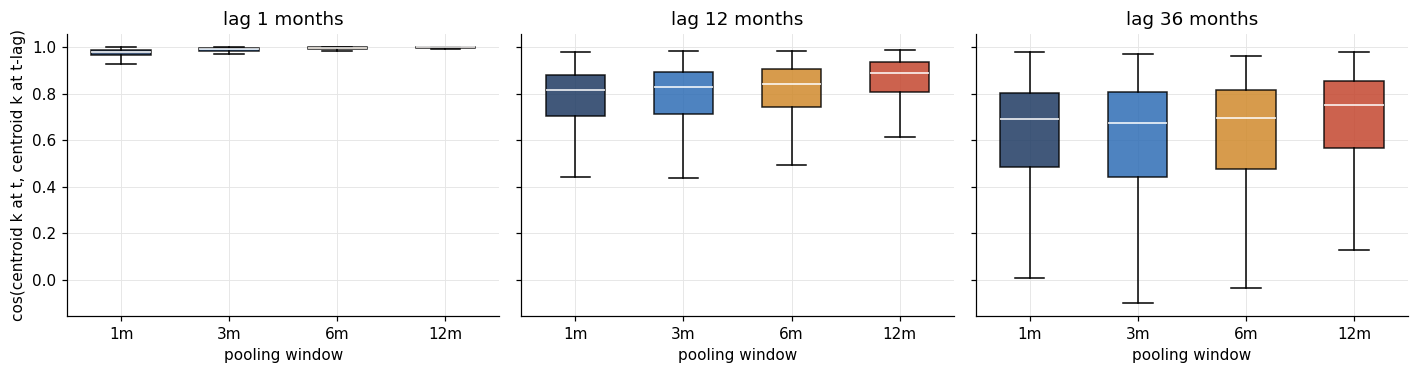

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, lag in zip(axes, [1, 12, 36]):
    data = [lag_cos(results[L]["C"], lag).ravel() for L in WINDOWS]
    bp = ax.boxplot(data, tick_labels=[f"{L}m" for L in WINDOWS], showfliers=False, patch_artist=True, widths=0.55)
    for patch, L in zip(bp["boxes"], WINDOWS):
        patch.set_facecolor(COLORS[L]); patch.set_alpha(0.85)
    for med in bp["medians"]:
        med.set_color("white")
    ax.set_title(f"lag {lag} months"); ax.set_xlabel("pooling window")
axes[0].set_ylabel("cos(centroid k at t, centroid k at t-lag)"); plt.tight_layout(); plt.show()

In [4]:
pl.DataFrame([{"window_months": L,
               **{f"median_lag{lag}": float(np.median(lag_cos(results[L]["C"], lag))) for lag in [1, 12, 36]},
               "share_lag36_below_0.5": float(np.mean(lag_cos(results[L]["C"], 36) < 0.5)),
               "jumps_cos_below_0.8": int((lag_cos(results[L]["C"], 1) < 0.8).sum()),
               "months_hungarian_reorders": results[L]["reorder"]} for L in WINDOWS])

window_months,median_lag1,median_lag12,median_lag36,share_lag36_below_0.5,jumps_cos_below_0.8,months_hungarian_reorders
i64,f64,f64,f64,f64,i64,i64
1,0.9781,0.8152,0.6899,0.2630,44,0
3,0.9915,0.8261,0.6746,0.3004,9,0
6,0.9956,0.8429,0.6972,0.2660,14,0
12,0.9982,0.8865,0.7525,0.2024,12,0


## Median 12-month centroid similarity over time

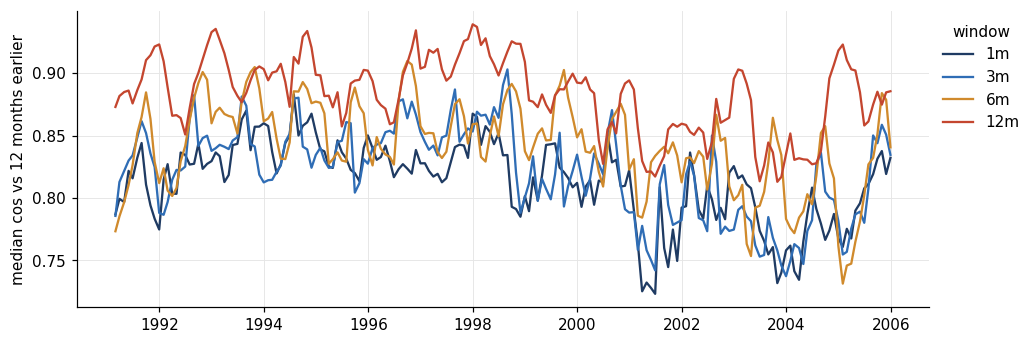

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for L in WINDOWS:
    ax.plot(dates[12:], np.median(lag_cos(results[L]["C"], 12), axis=1), color=COLORS[L], lw=1.5, label=f"{L}m")
ax.set_ylabel("median cos vs 12 months earlier"); ax.legend(frameon=False, title="window", loc="upper left", bbox_to_anchor=(1.0, 1.0)); plt.show()

## Fit to the current month: average best cosine of month-t firms to the centroids

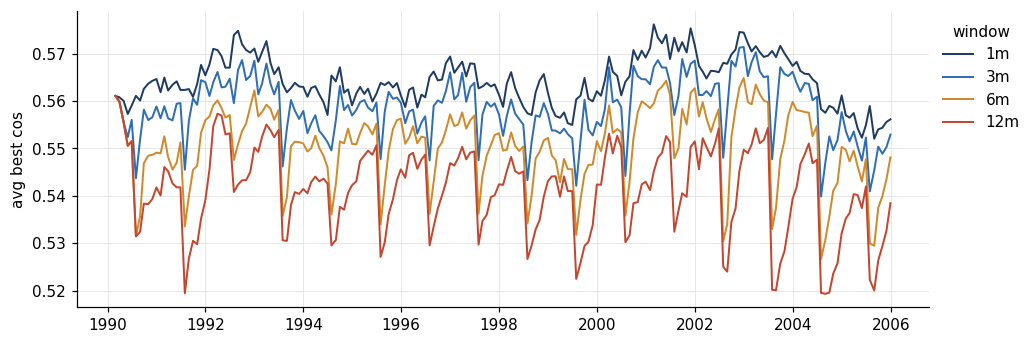

window_months,avg_best_cos,loss_vs_1m
i64,f64,f64
1,0.5643,0.0000
3,0.5585,0.0059
6,0.5505,0.0138
12,0.5412,0.0232


In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for L in WINDOWS:
    ax.plot(dates, results[L]["fit"], color=COLORS[L], lw=1.3, label=f"{L}m")
ax.set_ylabel("avg best cos"); ax.legend(frameon=False, title="window", loc="upper left", bbox_to_anchor=(1.0, 1.0)); plt.show()
pl.DataFrame({"window_months": WINDOWS,
              "avg_best_cos": [float(results[L]["fit"].mean()) for L in WINDOWS],
              "loss_vs_1m": [float(results[1]["fit"].mean() - results[L]["fit"].mean()) for L in WINDOWS]})

## Cluster sizes in the current month (share of firms)

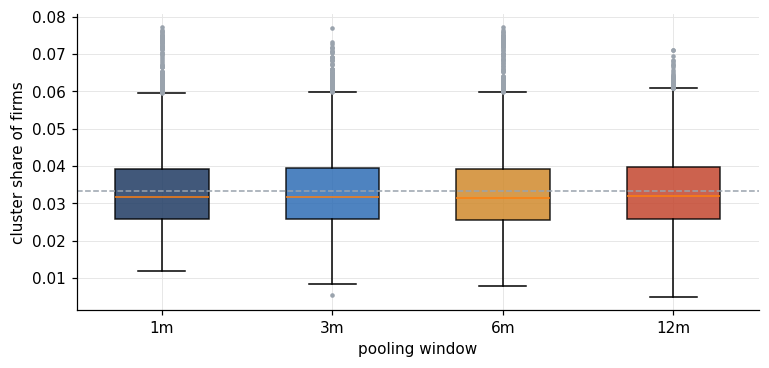

window_months,min_cluster_share,max_cluster_share,months_with_empty_cluster
i64,f64,f64,i64
1,0.0118,0.0772,0
3,0.0054,0.0770,0
6,0.0079,0.0772,0
12,0.0050,0.0711,0


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
data = [results[L]["sizes"].ravel() for L in WINDOWS]
bp = ax.boxplot(data, tick_labels=[f"{L}m" for L in WINDOWS], showfliers=True, patch_artist=True, widths=0.55,
                flierprops={"markersize": 2, "markerfacecolor": GREY, "markeredgecolor": GREY})
for patch, L in zip(bp["boxes"], WINDOWS):
    patch.set_facecolor(COLORS[L]); patch.set_alpha(0.85)
ax.axhline(1 / K, color=GREY, lw=1, ls="--")
ax.set_xlabel("pooling window"); ax.set_ylabel("cluster share of firms"); plt.show()
pl.DataFrame({"window_months": WINDOWS,
              "min_cluster_share": [float(results[L]["sizes"].min()) for L in WINDOWS],
              "max_cluster_share": [float(results[L]["sizes"].max()) for L in WINDOWS],
              "months_with_empty_cluster": [int((results[L]["sizes"] == 0).any(1).sum()) for L in WINDOWS]})